<a href="https://colab.research.google.com/github/Mahadeva77/DAV-Lab---4IK25CS097/blob/main/4ik25cs097_7(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
data = {
    'StudyHours': [1, 2, 3, 4, 5],
    'Attendance': [40, 20, 60, 60, 80],
    'Marks': [18, 17, 25, 33, 32]
}

df = pd.DataFrame(data)

print("Student Dataset:")
print(df)

Student Dataset:
   StudyHours  Attendance  Marks
0           1          40     18
1           2          20     17
2           3          60     25
3           4          60     33
4           5          80     32


In [3]:
X = df[['StudyHours', 'Attendance']]
y = df['Marks']

In [5]:
# 4. Create Multiple Linear Regression model
model = LinearRegression()
# 5. Train the model
model.fit(X, y)
# 6. Display intercept and coefficients
print("\nIntercept:", model.intercept_)
print("Study Hours Coefficient:", model.coef_[0])
print("Attendance Coefficient:", model.coef_[1])
# 7. Display regression equation
print("\nRegression Equation:")
print(
    f"Marks = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f} * StudyHours + "
    f"{model.coef_[1]:.2f} * Attendance"
)



Intercept: 10.000000000000004
Study Hours Coefficient: 3.049999999999999
Attendance Coefficient: 0.1125

Regression Equation:
Marks = 10.00 + 3.05 * StudyHours + 0.11 * Attendance


In [6]:
y_pred = model.predict(X)

df['PredictedMarks'] = y_pred

print("\nActual vs Predicted Marks:")
print(df)


Actual vs Predicted Marks:
   StudyHours  Attendance  Marks  PredictedMarks
0           1          40     18           17.55
1           2          20     17           18.35
2           3          60     25           25.90
3           4          60     33           28.95
4           5          80     32           34.25


In [8]:
new_student = pd.DataFrame({
    'StudyHours': [6],
    'Attendance': [90]
})
new_prediction = model.predict(new_student)
print("\nNew Student Details:")
print(new_student)


New Student Details:
   StudyHours  Attendance
0           6          90


In [9]:
print("Predicted Marks:", new_prediction[0])

Predicted Marks: 38.425


In [11]:
# 10. Calculate R-squared
r2 = r2_score(y, y_pred)
print("\nR-squared:", r2)
print("R-squared Percentage:", r2 * 100, "%")


R-squared: 0.8924778761061947
R-squared Percentage: 89.24778761061947 %


In [12]:
# 11. Calculate RMSE
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
print("\nMean Squared Error:", mse)
print("RMSE:", rmse)



Mean Squared Error: 4.860000000000001
RMSE: 2.2045407685048604


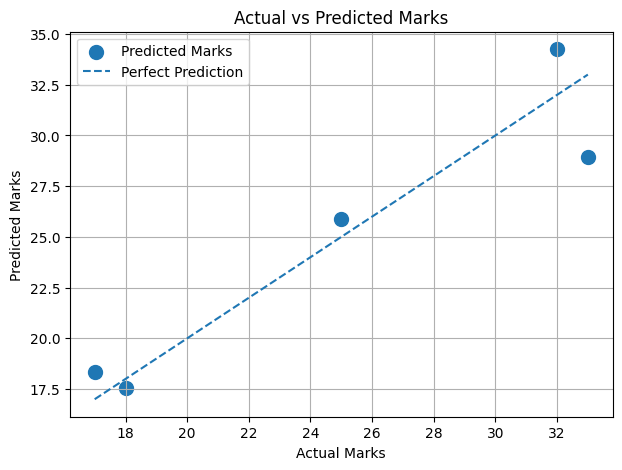

In [13]:
# 12. Visualization 1: Actual vs Predicted Marks
plt.figure(figsize=(7, 5))
plt.scatter(y, y_pred, s=100, label="Predicted Marks")
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    linestyle='--',
    label="Perfect Prediction"
)
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()
plt.grid()
plt.show()

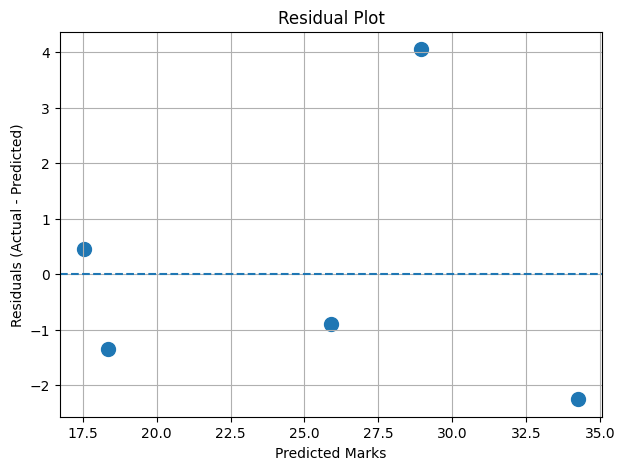

In [14]:
# 13. Visualization 2: Residual Plot
residuals = y - y_pred

plt.figure(figsize=(7, 5))

plt.scatter(y_pred, residuals, s=100)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Marks")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")

plt.grid()
plt.show()


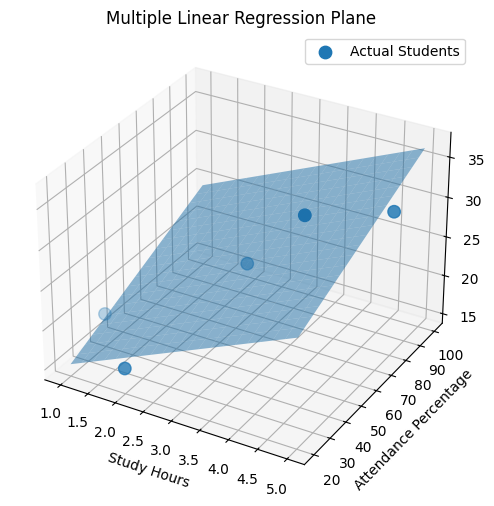

In [16]:
# 14. Visualization 3: Regression Plane
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
study_range = np.linspace(1, 5, 20)
attendance_range = np.linspace(20, 100, 20)
study_grid, attendance_grid = np.meshgrid(
    study_range,
    attendance_range
)
plane_input = pd.DataFrame({
    'StudyHours': study_grid.ravel(),
    'Attendance': attendance_grid.ravel()
})
marks_grid = model.predict(plane_input).reshape(study_grid.shape)
ax.plot_surface(
    study_grid,
    attendance_grid,
    marks_grid,
    alpha=0.5
)
ax.scatter(
    df['StudyHours'],
    df['Attendance'],
    df['Marks'],
    s=80,
    label="Actual Students"
)
ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendance Percentage")
ax.set_zlabel("Marks")
ax.set_title("Multiple Linear Regression Plane")
ax.legend()
plt.show()